In [1]:
from pathlib import Path
import os 

import pandas as pd
import numpy as np
import scanpy as sc 
import matplotlib.pyplot as plt 
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors
from matplotlib.patches import Patch
from matplotlib.font_manager import FontProperties

from dotenv import dotenv_values

In [2]:
# Setting up filepaths from config
CONFIG = dotenv_values("config.env") 
DATADIR = Path(CONFIG['DATADIR'])

OUTDIR = DATADIR / "publication" / "Fig_01"
os.makedirs(OUTDIR, exist_ok=True)

OBJECTS_DIR = DATADIR / "9_objects"
SC_ADATA_FP = OBJECTS_DIR / "singlecell" / "hypomap3d_singlecell_all.h5ad" 
ST_ADATA_FP = OBJECTS_DIR / "spatial" / 'hypomap3d_spatial_cell_level.h5ad'

In [3]:
adata_sc = sc.read_h5ad(SC_ADATA_FP)
adata_st = sc.read_h5ad(ST_ADATA_FP)

In [4]:
# switch to _sc UMAP 
adata_st.obsm["X_umap"] = adata_st.obsm["X_umap_sc"]

### Info dump

In [5]:
for i in range(1,6):
    num_n_clusters = adata_sc.obs.loc[~adata_sc.obs.L1_ID.str.contains("NN"), f"L{i}_ID"].nunique()
    num_nn_clusters = adata_sc.obs.loc[adata_sc.obs.L1_ID.str.contains("NN"), f"L{i}_ID"].nunique()
    print(f"L{i}: {num_n_clusters} N and {num_nn_clusters} NN clusters")

L1: 2 N and 4 NN clusters
L2: 68 N and 14 NN clusters
L3: 246 N and 28 NN clusters
L4: 670 N and 46 NN clusters
L5: 886 N and 46 NN clusters


## Plotting C only 

In [5]:
# old ones from before 

l1_colors = {
    'Gl1-1 Glut': "#8c564b",
    'Gb1-2 GABA': "#aa40fc",
    'NN1-4 Astro-Epen': "#17becf",
    'NN1-1 OPC-Oligo': "#ffbb78",
    'NN1-2 Immune': "#aec7e8",
    'NN1-3 Vascular': "#98df8a" 
}



In [10]:
scattersize = 0.3

/beegfs/home/mfeldmann/repos/HypoMap3D/.venv/lib/python3.11/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


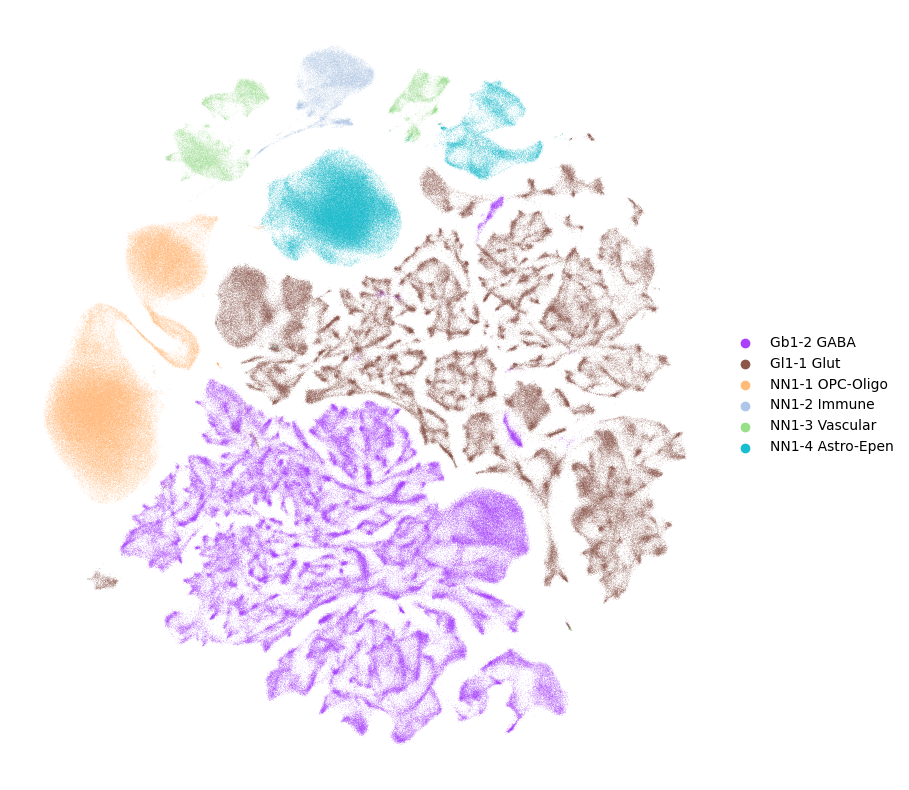

In [11]:

fig, ax = plt.subplots(figsize=(10, 10), ) 
sc.pl.umap(adata_sc[adata_sc.obs.IsControl], color="L1_descr", ax=ax, s=scattersize, show=False, palette=l1_colors )

# Rasterize only the scatter points (not text)
for coll in ax.collections:
    coll.set_rasterized(True)

# Customize: remove title, borders, ticks, labels
ax.set_title("")
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_aspect('equal')

fig.canvas.draw()

plt.savefig(OUTDIR / "umap_L1_C.pdf", format="pdf", dpi=300, bbox_inches="tight") 
plt.show()

## All cells C vs NC

In [ ]:
iscontrol_palette = {"True": "#2f3a56", "False": "#f6c667"}

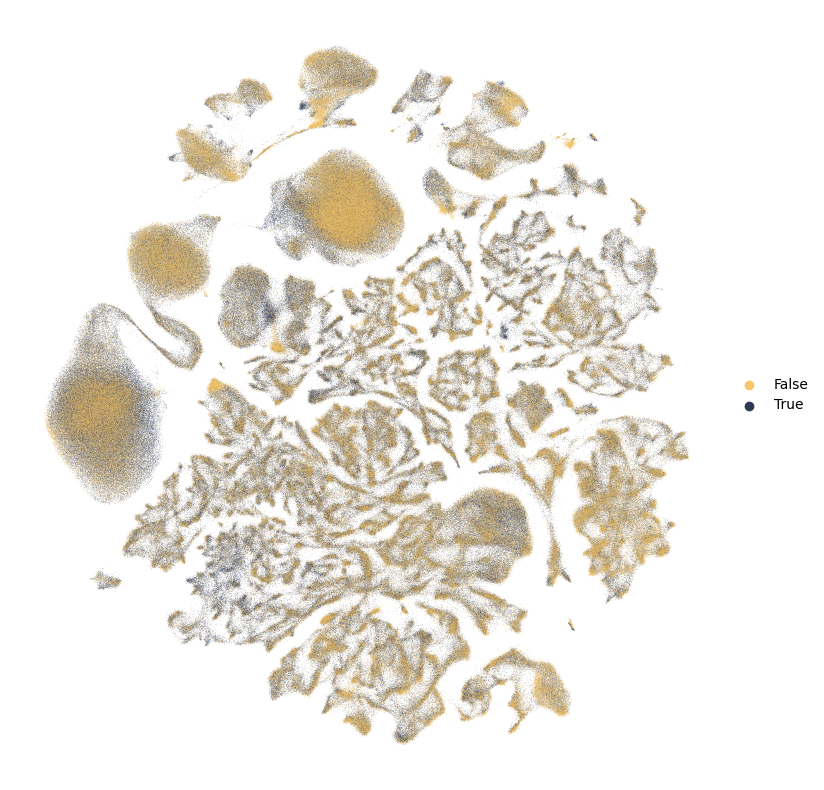

In [ ]:

fig, ax = plt.subplots(figsize=(10, 10), ) 
sc.pl.umap(adata_sc, color="IsControl", ax=ax, s=scattersize, show=False, palette=iscontrol_palette)

# Rasterize only the scatter points (not text)
for coll in ax.collections:
    coll.set_rasterized(True)

# Customize: remove title, borders, ticks, labels
ax.set_title("")
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_aspect('equal')

fig.canvas.draw()

plt.savefig(OUTDIR / "umap_L1_IsControl.pdf", format="pdf", dpi=300, bbox_inches="tight") 

## SC + ST

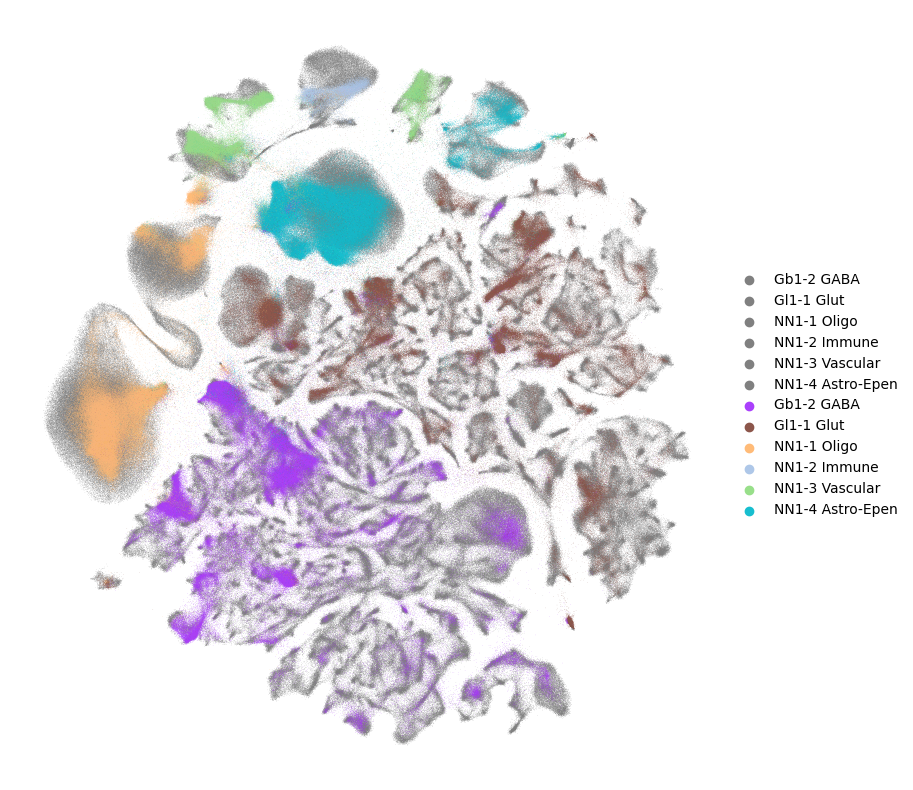

In [ ]:

# Create a high-DPI figure and axis
fig, ax = plt.subplots(figsize=(10, 10))

# 1. Plot SC cells in gray
sc.pl.umap(
    adata_sc,
    color="L1_descr",  
    ax=ax,
    show=False,
    palette=["grey"], 
    s=scattersize,
)

# 2. Plot ST cells with actual palette
sc.pl.umap(
    adata_st,
    color="L1_descr_max_p",
    palette=l1_colors,  # Your color dict
    ax=ax,
    show=False,
    s=scattersize,
)

# Rasterize all scatter points (collections are added to ax.collections in order)
for coll in ax.collections:
    coll.set_rasterized(True)

# Clean up plot appearance
ax.set_title("")
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_aspect('equal')

fig.canvas.draw()

# Save as vector with rasterized scatter points
plt.savefig(OUTDIR /  "umap_L1_all_gray_withST.pdf", format="pdf", dpi=300, bbox_inches="tight")

## Barplots

### SC

In [6]:
color_map_novelty = {

    "Present in HypoMap (2022)": "#88B2AA",
    "Present in Allen Brain Cell Atlas": "#DDDED6",
    "New data": "#116656"
    }


is_control_colors = {True: "#2f3a56", False: "#f6c667"}

# Cell types
cell_type_colors = {"Non-neuronal": "#deeaf2", "Neuronal": "#bed5e4"}

ylabel_size = 23

plt.rcParams['axes.grid'] = False

In [11]:
adata_sc.obs["is_part_of"] = "New data"
adata_sc.obs.loc[adata_sc.obs.Dataset.str.contains("SC1"), "is_part_of"] = "Present in HypoMap (2022)"
adata_sc.obs.loc[adata_sc.obs.Author == "YaoZ", "is_part_of"] = "Present in Allen Brain Cell Atlas"

adata_sc.obs["cell_type"] = "Neuronal"
adata_sc.obs.loc[adata_sc.obs.L1_descr.str.contains(r"NN"), "cell_type"] = "Non-neuronal"

adata_sc.obs["l1_control"] = adata_sc.obs.L1_descr.astype(str).copy()
adata_sc.obs.loc[adata_sc.obs.IsControl, "l1_control"] += " control"
adata_sc.obs.loc[~adata_sc.obs.IsControl, "l1_control"] += " non-control"

adata_sc.obs["IsControl_cell_type"] = "Control"
adata_sc.obs.loc[~adata_sc.obs.IsControl, "IsControl_cell_type"] = "Non-control"
adata_sc.obs.loc[adata_sc.obs.cell_type == "Neuronal", "IsControl_cell_type"] += " N"
adata_sc.obs.loc[adata_sc.obs.cell_type == "Non-neuronal", "IsControl_cell_type"] += " NN"

In [12]:
l1_control_order = [

 'Gl1-1 Glut control',
 'Gb1-2 GABA control',
 'NN1-1 OPC-Oligo control',
 'NN1-2 Immune control',
 'NN1-3 Vascular control',
 'NN1-4 Astro-Epen control',

 'Gl1-1 Glut non-control',
 'Gb1-2 GABA non-control',
 'NN1-1 OPC-Oligo non-control',
 'NN1-2 Immune non-control',
 'NN1-3 Vascular non-control',
 'NN1-4 Astro-Epen non-control',
]


In [13]:
trivial_order_l1 = [
    'Gl1-1 Glut control',
    'Gb1-2 GABA control',
    'NN1-1 OPC-Oligo control',
    'NN1-2 Immune control',
    'NN1-3 Vascular control',
    'NN1-4 Astro-Epen control',
]

priority = {" ".join(name.split()[:-1]): i for i, name in enumerate(trivial_order_l1)}

/tmp/ipykernel_2112862/3659266744.py:187: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


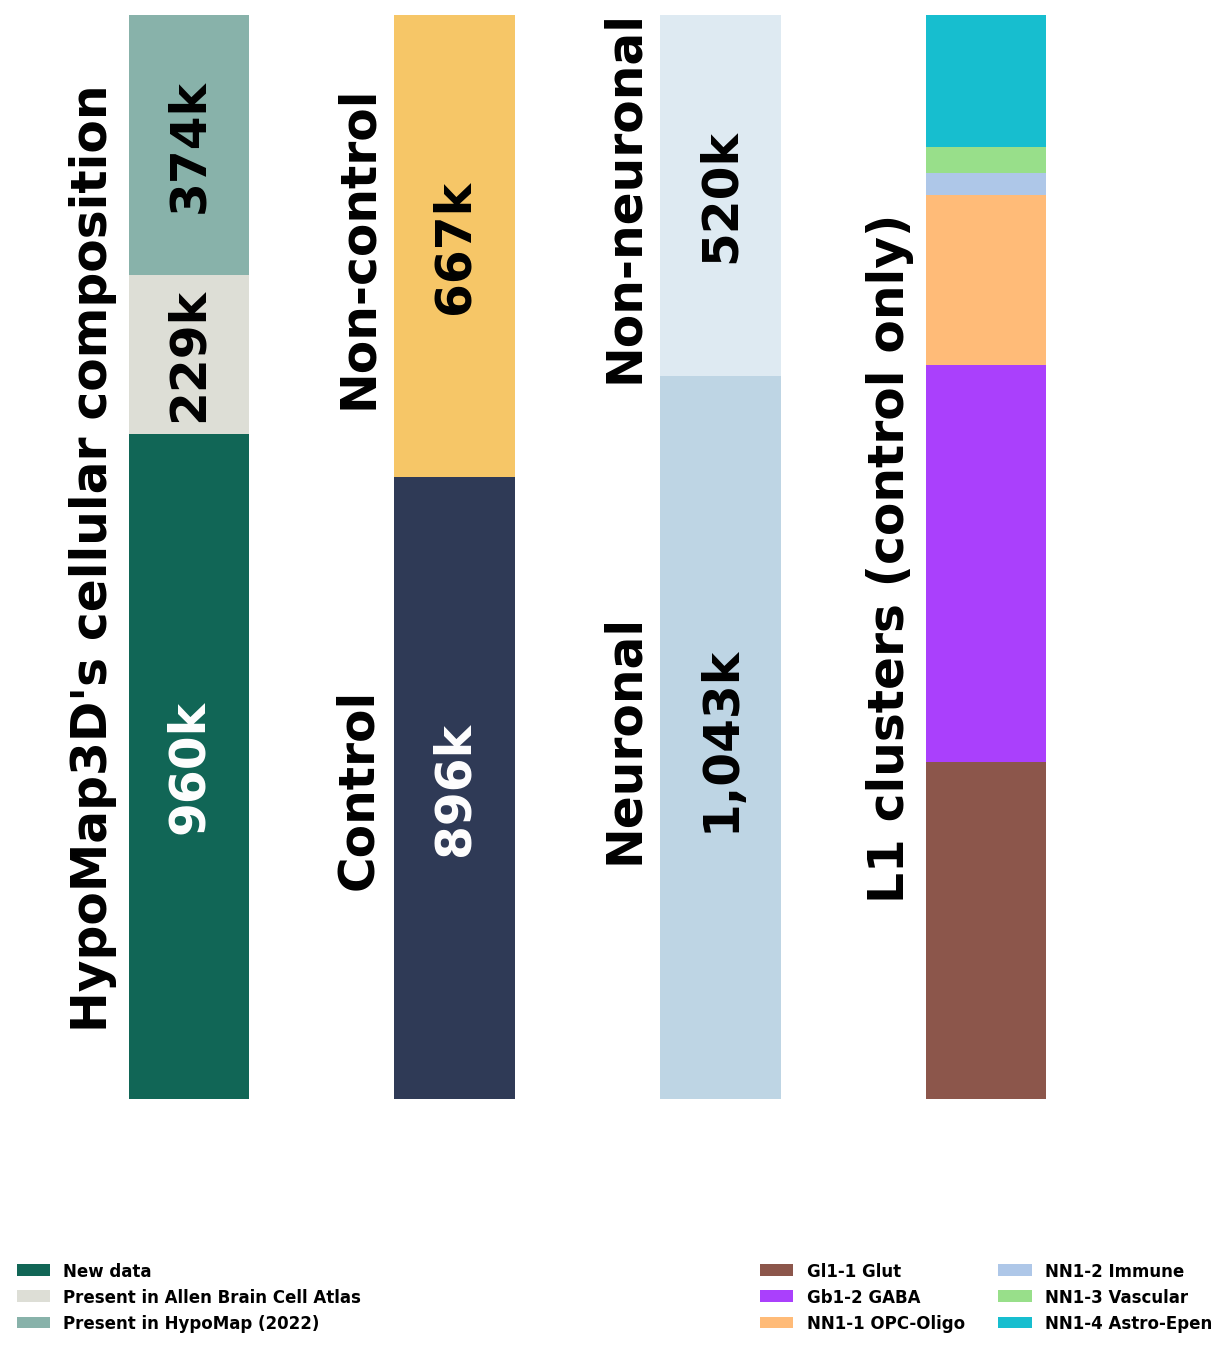

In [14]:
labelsize = 35

# --- Data Prep ---
df = adata_sc.obs.copy()

# Composition data
is_part_counts = df['is_part_of'].value_counts(normalize=True)
control_counts = df['IsControl'].value_counts(normalize=True)

# Group cell type by control status
celltype_by_control = df.groupby(['IsControl', 'cell_type']).size()
celltype_by_control = celltype_by_control / celltype_by_control.groupby(level=0).sum()

# L1 composition
l1_counts = df['L1_descr'].value_counts()
l1_ratios = l1_counts / l1_counts.sum()

# --- Plot Layout ---
fig = plt.figure(figsize=(12, 17))
gs = gridspec.GridSpec(2, 4, height_ratios=[1, 0.05], width_ratios=[0.08, 0.08, 0.08, 0.08], hspace=0.3, wspace=1)

# ----------------------
# 1. Dataset Composition
# ----------------------
ax1 = plt.subplot(gs[0, 0])
ax1.grid(False)
stack_order = list(color_map_novelty.keys())[::-1]
bottom = 0
for part in stack_order:
    value = is_part_counts.get(part, 0)
    color = color_map_novelty[part]
    ax1.bar(0, value, bottom=bottom, color=color, width=0.5, label=part)
    if value > 0:
        count = df[df['is_part_of'] == part].shape[0]
        label = f"{count // 1000}k"
        ax1.text(0, bottom + value / 2, label, ha='center', va='center',
                 fontsize=labelsize, fontweight='bold', rotation=90,
                 color='white' if part == "New data" else 'black')
    bottom += value
ax1.set_ylim(0, 1)
ax1.set_xticks([])
ax1.set_yticks([])
ax1.set_ylabel("HypoMap3D's cellular composition", fontweight='bold', fontsize=labelsize)
handles, labels = ax1.get_legend_handles_labels()
for spine in ax1.spines.values():
    spine.set_visible(False)

# ----------------------
# 2. Control vs Non-Control 
# ----------------------
ax2 = plt.subplot(gs[0, 1])
ax2.grid(False)
bottom = 0
for val in [True, False]:
    ratio = control_counts.get(val, 0)
    count = df[df['IsControl'] == val].shape[0]
    label = f"{count // 1000}k"  # only show count
    ax2.bar(0, ratio, bottom=bottom, color=is_control_colors[val], width=0.5)
    if ratio > 0:
        ax2.text(0, bottom + ratio / 2, label, ha='center', va='center',
                 fontsize=labelsize, fontweight='bold', rotation=90, color='white' if val else 'black')
    bottom += ratio
ax2.set_ylim(0, 1)
ax2.set_xticks([])
ax2.set_yticks([])

# Group labels (to left of bar)
ax2.text(-0.3, control_counts.get(True, 0) / 2, "Control",
         ha='right', va='center', fontsize=labelsize, fontweight='bold', color='black', rotation = 90)
ax2.text(-0.3, control_counts.get(True, 0) + control_counts.get(False, 0) / 2,
         "Non-control", ha='right', va='center', fontsize=labelsize, fontweight='bold', color='black', rotation = 90)


for spine in ax2.spines.values():
    spine.set_visible(False)

# ----------------------
# 3. Neuronal vs Non-Neuronal 
# ----------------------
ax3 = plt.subplot(gs[0, 2])
ax3.grid(False)
celltype_combined_counts = df['cell_type'].value_counts()
celltype_combined_ratios = celltype_combined_counts / celltype_combined_counts.sum()

order = [
    "Neuronal",
    "Non-neuronal"
]

bottom = 0
for key in order:
    value = celltype_combined_ratios.get(key, 0)
    count = celltype_combined_counts.get(key, 0)
    color = cell_type_colors.get(key, "gray")
    if value > 0:
        ax3.bar(0, value, bottom=bottom, color=color, width=0.5)
        ax3.text(0, bottom + value / 2, f"{count // 1000}k" if count < 1_000_000 else f"{str(count // 1000)[0]},{str(count // 1000)[1:]}k",
                 ha='center', va='center', fontsize=labelsize,
                 fontweight='bold', rotation=90, color='black')
        bottom += value

ax3.set_ylim(0, 1)
ax3.set_xticks([])
ax3.set_yticks([])

# Group labels (to left of bar)
ax3.text(-0.3, celltype_combined_ratios.get("Neuronal", 0) / 2, "Neuronal",
         ha='right', va='center', fontsize=labelsize, fontweight='bold', color='black', rotation = 90)
ax3.text(-0.3, celltype_combined_ratios.get("Neuronal", 0) + celltype_combined_ratios.get("Non-neuronal", 0) / 2,
         "Non-neuronal", ha='right', va='center', fontsize=labelsize, fontweight='bold', color='black', rotation = 90)


for spine in ax3.spines.values():
    spine.set_visible(False)

# ----------------------
# 4. L1 Stacked Bar Plot (control cells only)
# ----------------------
ax4 = plt.subplot(gs[0, 3])
ax4.grid(False)

# Filter to control cells only
control_df = df[df['IsControl'] == True]

# Keep only entries in l1_control with 'control' suffix
control_l1_series = control_df['l1_control']
control_l1_series = control_l1_series[control_l1_series.str.endswith('control')]
control_l1_series = control_l1_series.astype(pd.CategoricalDtype(categories=trivial_order_l1, ordered=True)).sort_values()

# Sort by cluster name (before " control")
sorted_l1_control_keys = [" ".join(x.split()[:-1]) for x in control_l1_series.unique()]
sorted_l1_control_keys = control_l1_series.unique()

# Get counts and ratios
l1_control_counts = control_l1_series.value_counts()
l1_control_ratios = l1_control_counts / l1_control_counts.sum()

bottom = 0
for key in sorted_l1_control_keys:
    ratio = l1_control_ratios.get(key, 0)

    # Get base L1 cluster name
    cluster_name = " ".join(key.split()[:-1])
    color = l1_colors.get(cluster_name, "gray")  # fallback color

    if ratio > 0:
        ax4.bar(0, ratio, bottom=bottom, color=color, width=0.5)
        bottom += ratio

ax4.set_ylim(0, 1)
ax4.set_xticks([])
ax4.set_yticks([])
ax4.set_ylabel("L1 clusters (control only)", fontweight='bold', fontsize=labelsize)
for spine in ax4.spines.values():
    spine.set_visible(False)

# ----------------------
# Legend
# ----------------------
legend_ax = plt.subplot(gs[1, 0])
legend_ax.axis('off')
legend = legend_ax.legend(handles=handles, labels=labels, loc='center', ncol=1,
                          frameon=False, fontsize='large', title=None)
for txt in legend.get_texts():
    txt.set_fontweight('bold')

# ----------------------
# Legend for L1 clusters (row 1 of GridSpec, col 3)
# ----------------------

legend_ax2 = plt.subplot(gs[1, 3])
legend_ax2.axis('off')

# Alphabetically sort by cluster name
#sorted_l1_items = sorted(l1_colors.items(), key=lambda x: x[0])
sorted_l1_items = sorted(l1_colors.items(), key=lambda x: priority[x[0]])

# Create legend handles
l1_legend_handles = [Patch(facecolor=color, label=label) for label, color in sorted_l1_items]

legend2 = legend_ax2.legend(handles=l1_legend_handles, loc='center', ncol=2,
                            frameon=False, fontsize='large', title=None)

for txt in legend2.get_texts():
    txt.set_fontweight('bold')
    
plt.tight_layout()
plt.savefig(OUTDIR /  "fig1_a_bars.pdf", format="pdf", dpi=300, bbox_inches="tight") 
plt.show()


### ST

In [ ]:
st_author_colors = {
    "Langlieb": "#b45f06",
    "Zhang": "#ad5d5d" ,
    "Yao": "#DDDED6",
    "OpenST": "#116656",

}

In [ ]:
adata_st.obs.Author = adata_st.obs.Author.replace({"Bauder": "OpenST"})

/tmp/ipykernel_856535/3821932518.py:1: FutureWarning: The behavior of Series.replace (and DataFrame.replace) with CategoricalDtype is deprecated. In a future version, replace will only be used for cases that preserve the categories. To change the categories, use ser.cat.rename_categories instead.
  adata_st.obs.Author = adata_st.obs.Author.replace({"Bauder": "OpenST"})


In [ ]:
author_counts = adata_st.obs.Author.value_counts()
author_counts

Author
Zhang       529710
Yao         510968
Langlieb    213319
OpenST      147316
Name: count, dtype: int64

/tmp/ipykernel_856535/1271342167.py:52: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


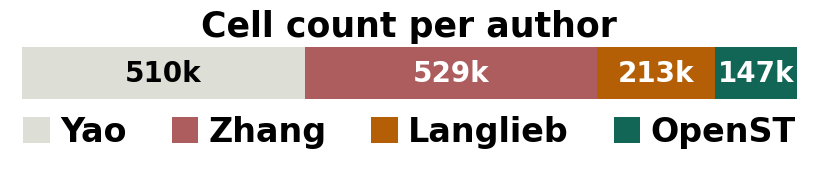

In [ ]:

labelsize = 25
numberssize = 20

# Define desired order
desired_order = ["Yao", "Zhang", "Langlieb", "OpenST"]

# Reindex author_counts to follow desired order
author_counts_ordered = author_counts.reindex(desired_order).fillna(0).astype(int)

# Update labels accordingly
author_labels_ordered = [f"{count // 1000}k" for count in author_counts_ordered]

# --- Figure and GridSpec layout ---
fig = plt.figure(figsize=(10, 1.5))
gs = gridspec.GridSpec(nrows=2, ncols=1, height_ratios=[0.3, 0.3], hspace=0.05)

# --- 1. Plot: Horizontal stacked bar ---
ax1 = fig.add_subplot(gs[0, 0])
left = 0
bars = []

for author, count, label in zip(author_counts_ordered.index, author_counts_ordered.values, author_labels_ordered):
    color = st_author_colors.get(author, "gray")  # fallback color
    bar = ax1.barh(0, count, left=left, label=author, color=color)
    bars.append(bar[0])
    ax1.text(left + count / 2, 0, label, ha='center', va='center',
             fontsize=numberssize, fontweight='bold', color='white' if author in ["Zhang", "Langlieb", "OpenST"] else 'black')
    left += count

# Format plot
ax1.set_yticks([])
ax1.set_xticks([])
ax1.set_xlim(0, left)
ax1.set_title("Cell count per author", fontweight='bold', fontsize=labelsize)

for spine in ax1.spines.values():
    spine.set_visible(False)

# --- 2. Legend below ---
ax_legend = fig.add_subplot(gs[1, 0])
ax_legend.axis("off")
bold_font = FontProperties(weight='bold', size = labelsize - 1)
legend = ax_legend.legend(handles=bars, labels=list(author_counts_ordered.index), loc='center', 
                    ncol=len(author_counts_ordered), frameon=False, fontsize='large',
                    prop=bold_font,
                    handletextpad=0.3,    # space between color box and text
                    columnspacing=1.35,    # space between columns
                    borderaxespad=0.0,
                    handlelength=0.8,
                    handleheight=0.8,)

plt.tight_layout()
plt.savefig(OUTDIR / "ST_cell_count_per_author_hbar.pdf", format="pdf", dpi=300, bbox_inches="tight")
plt.show()
